## Ćwiczenie 9: usuwanie zakłóceń (Notch Filter)
**Cel:** Zastosowanie analizy widmowej do rozwiązania rzeczywistego problemu inżynierskiego – usunięcia sprzętowych pasów interferencyjnych z obrazu medycznego, których nie można usunąć klasycznymi filtrami przestrzennymi.

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, color, filters

plt.rcParams['figure.figsize'] = (10, 5)

#### Krok 1: Wczytanie danych (symulacja uszkodzonej aparatury)
Wczytamy zdrowy przekrój MRI, a następnie nałożymy na niego silne, prążkowane zakłócenie. Tego typu artefakty (pasy) często pojawiają się przy uszkodzeniach okablowania, złym uziemieniu skanera lub błędach matrycy.

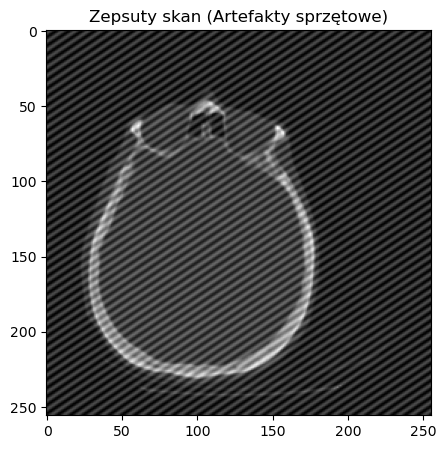

In [17]:
# Pobieramy obraz 256x256
clean_mri = data.brain()[1, :, :]

# Generujemy sztuczne zakłócenie (sinusoidalną siatkę ukośną)
rows, cols = clean_mri.shape
Y, X = np.indices((rows, cols))
# Częstotliwość zakłócenia
freq_y, freq_x = 45, 30 
noise_ampl = 0.2 * clean_mri.max()
noise = noise_ampl * np.sin(2 * np.pi * (freq_y * Y / rows + freq_x * X / cols))

# Dodajemy szum do obrazu i normalizujemy do przedziału [0, 1]
noisy_mri = clean_mri + noise
noisy_mri = (noisy_mri - noisy_mri.min()) / (noisy_mri.max() - noisy_mri.min())

plt.title('Zepsuty skan (Artefakty sprzętowe)')
plt.imshow(noisy_mri, cmap='gray')
plt.show()

#### Krok 2: Próba ratunku klasycznymi metodami 
Spróbuj usunąć ostre krawędzie pasów klasycznym, silnym rozmyciem Gaussa.

In [22]:
#Implementacja filtra Gaussa
#blurred_mri = 

'''
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(noisy_mri, cmap='gray'); ax[0].set_title('Oryginał z pasami')
ax[1].imshow(blurred_mri, cmap='gray'); ax[1].set_title('Rozmycie Gaussa (Sigma=3)')
plt.show()
'''

"\nfig, ax = plt.subplots(1, 2, figsize=(12, 6))\nax[0].imshow(noisy_mri, cmap='gray'); ax[0].set_title('Oryginał z pasami')\nax[1].imshow(blurred_mri, cmap='gray'); ax[1].set_title('Rozmycie Gaussa (Sigma=3)')\nplt.show()\n"

#### Krok 3: Diagnoza w domenie częstotliwości (FFT)
**Zadanie:** Przejdź do dziedziny częstotliwości. Policz 2D FFT, wyśrodkuj je i wyświetl widmo amplitudowe w skali logarytmicznej.

In [ ]:
# WYKONAJ: Oblicz wycentrowane widmo z obrazu 'noisy_mri'
# === TWÓJ KÓD TUTAJ ===
fft_shifted = np.zeros_like(noisy_mri)         # <- Zastąp: fft2 + fftshift
magnitude_spectrum = np.zeros_like(noisy_mri)  # <- Zastąp: log(1 + abs(...))
# ======================

# plt.title('Widmo zepsutego skanu (Zlokalizuj anomalię!)')
# plt.imshow(magnitude_spectrum, cmap='gray')
# plt.show()

#### Krok 4: Filtr pasmowoprzepustowy (Notch Filter)
Spójrz na widmo powyżej. Widzisz dużą, białą gwiazdę na środku (to nasz pacjent). Zauważ jednak **dwie małe, bardzo jasne kropki**, ułożone symetrycznie na ukos od centrum. To właśnie one reprezentują całą siatkę pasków na oryginalnym zdjęciu!

**Zadanie:** 
1. Odczytaj (w przybliżeniu, najeżdżając kursorem na wykresie lub wyliczając matematycznie ze współrzędnych z kroku 1) położenie (y, x) tych dwóch kropek.
2. Stwórz maskę, która jest wszędzie równa 1 (przepuszcza wszystko), ale w miejscu tych dwóch kropek (np. w małym promieniu r=3 wokół nich) ma wartość 0 (odcięcie).

In [ ]:
# Tworzymy maskę złożoną z samych jedynek
notch_mask = np.ones_like(noisy_mri)

# Środek macierzy (dla obrazu 256x256 to punkt [128, 128])
center_y, center_x = rows // 2, cols // 2

# WYKONAJ: Ustaw zera (0) w masce notch_mask w dwóch punktach odpowiadających jasnym kropkom zakłóceń.
# Podpowiedź: Częstotliwości szumu zdefiniowaliśmy na górze jako freq_y=45, freq_x=30.
# Pik 1 znajduje się na wsp.: center_y + freq_y, center_x + freq_x
# Pik 2 znajduje się na wsp.: center_y - freq_y, center_x - freq_x

# === TWÓJ KÓD TUTAJ ===
# np. Wytnij małe kwadraty 5x5 wokół piku 1 i piku 2 używając slicingu (cięcia tablic) np. mask[y1:y2, x1:x2] = 0

# ======================

plt.title('Maska Zaporowa (Notch Filter)')
plt.imshow(notch_mask, cmap='gray')
plt.show()

#### Krok 5: Rekonstrukcja obrazu
Teraz połączymy maskę z widmem (mnożenie), by fizycznie wyzerować sygnał błędu, a następnie zrekonstruujemy obraz operacją IFFT.

In [ ]:
# 1. Usunięcie wadliwych fal
filtered_fft_shifted = fft_shifted * notch_mask

# WYKONAJ: Cofnij przesunięcie i wykonaj IFFT, odzyskując wyczyszczony obraz
# === TWÓJ KÓD TUTAJ ===
cleaned_mri = np.zeros_like(noisy_mri) # <- Zastąp: ifft2, ifftshift, abs()
# ======================

# WIZUALIZACJA KOŃCOWA
# fig, ax = plt.subplots(1, 2, figsize=(14, 7))
# ax[0].imshow(noisy_mri, cmap='gray'); ax[0].set_title('Obraz z defektem aparatu')
# ax[1].imshow(cleaned_mri, cmap='gray'); ax[1].set_title('Uzdrowiony obraz (Sukces FFT!)')
# plt.show()